# Phase 12.3 - Gym signed leverage RL (GBPUSD)

Actor-Critic en `gymnasium` con accion firmada discreta: `[-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2]`.

Objetivo: que el modelo aprenda **direccion + apalancamiento** (no solo magnitud).


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

ROOT = Path('.')
PHASE12 = ROOT / 'phases/phase12_leverage_rl'
RUN_SCRIPT = PHASE12 / 'run_phase12_3_gym_signed_leverage.py'
OUT_DIR = PHASE12 / 'output_phase12_3_gym_signed_leverage_GBPUSD'

OUT_SUMMARY = OUT_DIR / 'GBPUSD_phase12_3_summary.json'
OUT_COMPARE = OUT_DIR / 'GBPUSD_phase12_3_policy_comparison.csv'
OUT_TRIALS = OUT_DIR / 'GBPUSD_phase12_3_trials.csv'
OUT_PRED = OUT_DIR / 'GBPUSD_phase12_3_holdout_predictions.csv'


In [2]:
# Ejecutar desde terminal con conda:
# source ~/miniconda3/etc/profile.d/conda.sh && conda activate torch-gpu-pip && python "${RUN_SCRIPT}"

print('Script:', RUN_SCRIPT)
print('Output dir:', OUT_DIR)
print('Summary exists:', OUT_SUMMARY.exists())


Script: ./phases/phase12_leverage_rl/run_phase12_3_gym_signed_leverage.py
Output dir: ./phases/phase12_leverage_rl/output_phase12_3_gym_signed_leverage_GBPUSD
Summary exists: True


In [3]:
summary = json.loads(OUT_SUMMARY.read_text())
compare_df = pd.read_csv(OUT_COMPARE)
trials_df = pd.read_csv(OUT_TRIALS).sort_values('val_score_q', ascending=False)

display(pd.DataFrame([summary['best_trial_row']]))
display(compare_df)
display(trials_df)


,trial,risk_penalty,turnover_penalty,entropy_coef,val_score_q,val_avg_q,val_sharpe_q,val_avg_abs_lev_q,val_trade_rate_q,holdout_cum_q,holdout_cum_behavior_1x,holdout_cum_behavior_2x
0,t0_neutral,0.00002,0.0,0.008,7.686983,0.000669,6.459802,0.827193,0.956725,-0.412977,0.58665,1.1733


,split,policy,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,trade_rate,avg_turnover,sharpe_ann,win_rate_trades,avg_abs_lev,avg_abs_lev_on_trade
0,validation,behavior_1x,0.337427,0.332445,0.000228,0.390024,0.005181,0.361988,0.367251,3.423678,0.531502,0.361988,1.000000
1,validation,behavior_2x,0.337427,0.332445,0.000456,0.780049,0.010362,0.361988,0.734503,3.423678,0.531502,0.723977,2.000000
2,validation,gym_signed_leverage,0.429240,0.314736,0.000669,1.143604,0.008051,0.956725,0.659649,6.459802,0.500611,0.827193,0.864609
3,holdout,behavior_1x,0.326196,0.324551,0.000163,0.586650,0.004038,0.360400,0.325918,3.141828,0.547840,0.360400,1.000000
4,holdout,behavior_2x,0.326196,0.324551,0.000326,1.173300,0.008076,0.360400,0.651835,3.141828,0.547840,0.720801,2.000000
5,holdout,gym_signed_leverage,0.421580,0.334272,-0.000115,-0.412977,0.006880,0.945217,1.032258,-1.298162,0.494851,1.444800,1.528538


,trial,risk_penalty,turnover_penalty,entropy_coef,val_score_q,val_avg_q,val_sharpe_q,val_avg_abs_lev_q,val_trade_rate_q,holdout_cum_q,holdout_cum_behavior_1x,holdout_cum_behavior_2x
0,t0_neutral,0.00002,0.00000,0.008,7.686983,0.000669,6.459802,0.827193,0.956725,-0.412977,0.58665,1.1733
1,t1_turnover_light,0.00002,0.00002,0.008,3.585955,0.000312,3.003481,1.179825,0.987135,-0.455806,0.58665,1.1733
2,t3_risk_med,0.00005,0.00002,0.006,1.505569,0.000117,2.049555,0.677485,0.376608,-0.240128,0.58665,1.1733
3,t2_turnover_med,0.00002,0.00005,0.006,0.125288,0.000008,0.108278,0.928655,0.998830,-1.024588,0.58665,1.1733


In [4]:
pred = pd.read_csv(OUT_PRED)

print('sign_eq_vs_behavior_1x:', (pred['action_gym_signed_leverage'] == pred['action_behavior_1x']).mean())
print('lev_eq_vs_behavior_1x:', (pred['lev_gym_signed_leverage'] == pred['lev_behavior_1x']).mean())
print('trade_rate_gym:', (pred['lev_gym_signed_leverage'] != 0).mean())
print('avg_abs_lev_gym:', pred['lev_gym_signed_leverage'].abs().mean())

lev_counts = pred['lev_gym_signed_leverage'].round(2).value_counts().sort_index()
display(lev_counts.to_frame('count'))


sign_eq_vs_behavior_1x: 0.2661290322580645
lev_eq_vs_behavior_1x: 0.08731924360400445
trade_rate_gym: 0.9452169076751946
avg_abs_lev_gym: 1.4447997775305896


,count
lev_gym_signed_leverage,
-2.0,1179
-1.5,42
-1.0,121
0.0,197
0.5,618
1.0,533
1.5,1
2.0,905


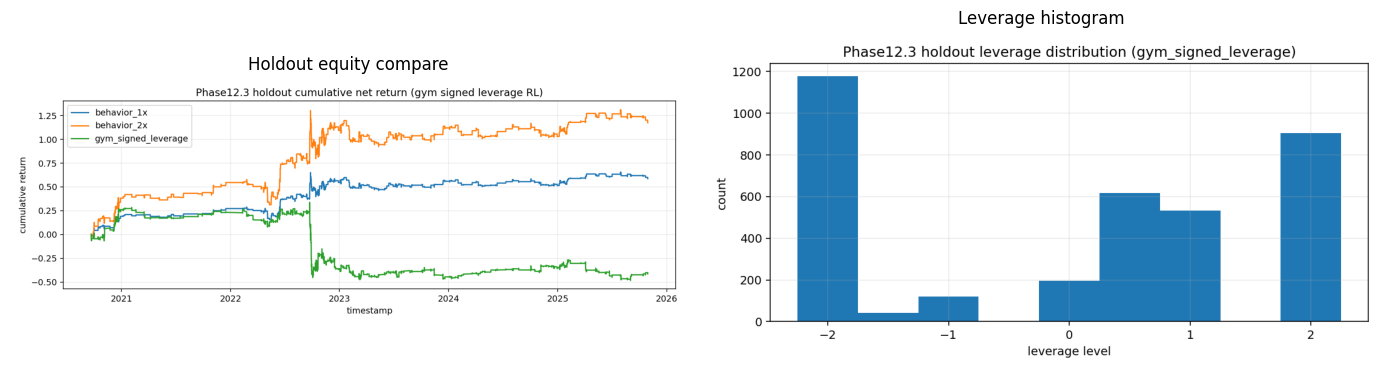

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(mpimg.imread(OUT_DIR / 'GBPUSD_phase12_3_holdout_equity_compare.png'))
axes[0].axis('off')
axes[0].set_title('Holdout equity compare')

axes[1].imshow(mpimg.imread(OUT_DIR / 'GBPUSD_phase12_3_holdout_leverage_hist.png'))
axes[1].axis('off')
axes[1].set_title('Leverage histogram')

plt.tight_layout()
